# Tutorial 1: A WRTDS analysis from start to finish

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gopalam/PyEGRET/blob/main/tutorials/01_choptank_walkthrough.ipynb)

This notebook runs a complete WRTDS trend analysis on the dataset that ships
with the R package EGRET: nitrate plus nitrite in the **Choptank River near
Greensboro, Maryland** (USGS site 01491000), from October 1979 through
September 2011. It follows the same path as EGRET's own introductory vignette,
so if you have used EGRET in R, every step will be familiar; if you have not,
the notebook explains each one as it goes.

By the end you will have fitted a WRTDS model, checked that it fits, read off
annual and flow-normalized results, looked at how the concentration-discharge
relationship has changed over three decades, separated the part of the trend
caused by the watershed from the part caused by streamflow, and produced
WRTDS-Kalman daily estimates. The whole notebook runs in about a minute.

For the method itself, the EGRET user guide (Hirsch and De Cicco, 2015,
<https://doi.org/10.3133/tm4A10>) remains the best reference, and the original
paper is Hirsch, Moyer and Archfield (2010),
<https://doi.org/10.1111/j.1752-1688.2010.00482.x>.

## Setting up

The first cell finds PyEGRET. If you downloaded the repository and opened this
notebook from its `tutorials` folder, it uses the copy one folder up, and
nothing needs to be installed. If you opened it somewhere else, such as Google
Colab, it installs PyEGRET from GitHub first.

In [1]:
import os
import sys

# If this notebook sits in PyEGRET/tutorials, PyEGRET is one folder up and is
# used straight from there, with nothing installed. Anywhere else (Google
# Colab, say) it is installed from GitHub, and the data are read from GitHub.
HERE = os.path.abspath("")
ROOT = os.path.dirname(HERE)
if os.path.isdir(os.path.join(ROOT, "pyegret")):
    sys.path.insert(0, ROOT)
else:
    try:
        import pyegret
    except ImportError:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check",
                        "pyegret @ git+https://github.com/gopalam/PyEGRET"], check=True)

# The example data: the data folder next to this notebook, or else GitHub.
DATA = os.path.join(HERE, "data")
if not os.path.isdir(DATA):
    DATA = "https://raw.githubusercontent.com/gopalam/PyEGRET/main/tutorials/data"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyegret

print("PyEGRET", pyegret.__version__)

PyEGRET 0.1.0


## 1. Reading the data

WRTDS needs two records from the same site: a **daily discharge** record, which
should cover at least the whole period of sampling, and a set of
**water-quality samples**. Here they are two plain CSV files in the format
PyEGRET reads, which is also the format you would put your own data in
(Tutorial 2 covers that in detail).

In [2]:
from pyegret.data.read_user import read_user_daily, read_user_sample

daily = read_user_daily(DATA + "/choptank_daily.csv")
sample = read_user_sample(DATA + "/choptank_sample.csv")

The input discharge are assumed to be in cubic feet per second, if they are in cubic meters per second, then the call to read_user_daily should specify q_unit=2


The message is a reminder that, as in R, `read_user_daily` assumes discharge
in cubic feet per second, which is right for this file. Internally PyEGRET
works in cubic meters per second, so the `Q` column below is already
converted. The reader also adds everything WRTDS needs: the log of discharge,
the decimal year, the day of the year, and 7- and 30-day running means.

In [3]:
daily.head()

,Date,Q,Qualifier,LogQ,DecYear,Month,Day,MonthSeq,Julian,waterYear,SinDY,CosDY,i,Q7,Q30
0,1979-10-01,1.897229,,0.640394,1979.747945,10,275,1558,47389,1980,-0.999917,-0.012910,1,NaN,NaN
1,1979-10-02,2.010496,,0.698382,1979.750685,10,276,1558,47390,1980,-0.999991,0.004304,2,NaN,NaN
2,1979-10-03,2.746734,,1.010413,1979.753425,10,277,1558,47391,1980,-0.999769,0.021516,3,NaN,NaN
3,1979-10-04,3.851091,,1.348357,1979.756164,10,278,1558,47392,1980,-0.999250,0.038722,4,NaN,NaN
4,1979-10-05,4.077626,,1.405515,1979.758904,10,279,1558,47393,1980,-0.998435,0.055917,5,NaN,NaN


Each sample becomes a pair of bounds, `ConcLow` and `ConcHigh`. For a measured
value the two are equal; for a value reported as "less than" the reporting
limit, `ConcLow` is zero and `ConcHigh` is the limit, and `Uncen` is 0. The
Choptank record has 606 samples and only one of them is censored.

In [4]:
sample.head()

,Date,ConcLow,ConcHigh,Uncen,DecYear,Month,Day,MonthSeq,Julian,waterYear,SinDY,CosDY,ConcAve,LogConcLow,LogConcHigh
0,1979-10-24,0.62,0.62,1,1979.810959,10,298,1558,47412,1980,-0.927542,0.373720,0.62,-0.478036,-0.478036
1,1979-12-05,1.40,1.40,1,1979.926027,12,340,1560,47454,1980,-0.448229,0.893919,1.40,0.336472,0.336472
2,1979-12-21,1.20,1.20,1,1979.969863,12,356,1560,47470,1980,-0.188227,0.982126,1.20,0.182322,0.182322
3,1980-01-24,0.84,0.84,1,1980.062842,1,24,1561,47504,1980,0.384665,0.923056,0.84,-0.174353,-0.174353
4,1980-02-25,1.20,1.20,1,1980.150273,2,56,1562,47536,1980,0.810025,0.586396,1.20,0.182322,0.182322


## 2. The eList

Everything about one site and one constituent travels together in an
**eList**. In PyEGRET that is an ordinary Python dictionary, with the same
element names as in R: `INFO` for site metadata, `Daily`, `Sample`, and later
the fitted surface. `INFO` needs at least a short name for the site and for the
constituent, which label tables and plots; the drainage area is used by a few
outputs.

`merge_report` builds the eList and attaches to each sample the discharge of
its day.

In [5]:
from pyegret import merge_report, describe_elist

info = pd.DataFrame([{
    "station_nm": "Choptank River near Greensboro, MD",
    "shortName": "Choptank River",
    "paramShortName": "Inorganic nitrogen (nitrate and nitrite)",
    "drainSqKm": 292.67,
}])

elist = merge_report(info, daily, sample)
print(describe_elist(elist))
print(list(elist.keys()))

eList
  Site:    Choptank River near Greensboro, MD
  Daily:   1979-10-01 to 2011-09-30 (11688 days)
  Samples: 606
  Model:   no
['INFO', 'Daily', 'Sample', 'surfaces', 'vector_year', 'vector_logQ']


## 3. Looking at the data first

Before fitting anything it is worth looking at the record.
`multi_plot_data_overview` draws EGRET's four standard views: concentration
against discharge, concentration by month, concentration over time, and the
discharge on sampled days compared with all days. The last panel matters more
than it looks: if samples were taken mostly at high or low flow, the model has
less to go on at the other end.

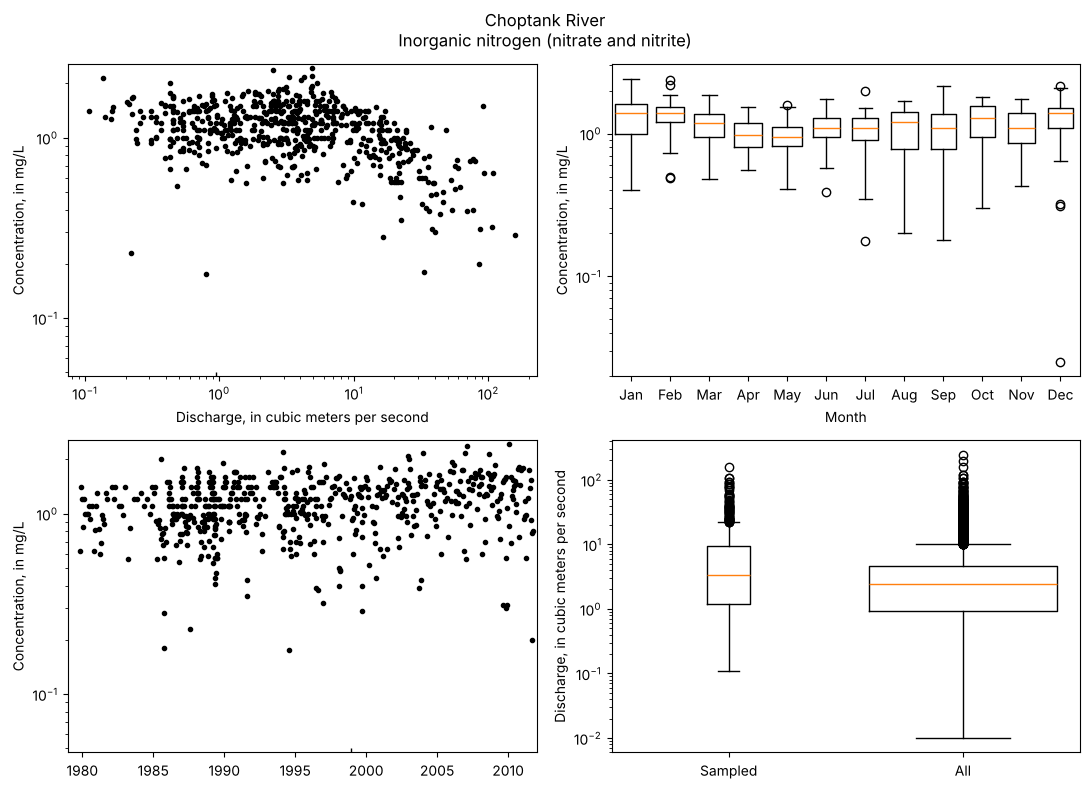

In [6]:
import pyegret.plots as plots

fig, axes = plots.multi_plot_data_overview(elist)

Nitrate in the Choptank is highest at moderate flows and diluted at the
highest ones, it is highest in winter and lowest in spring, and it has risen
since 1980. Those are the three dimensions WRTDS models at once: discharge,
season and time. The last panel shows that samples were taken over most of the
range of flows, somewhat more often at higher flows than the record as a
whole, and never at the very lowest flows.

## 4. Fitting the WRTDS model

`model_estimation` fits the model. For every point on a grid of dates and
discharges it fits a weighted regression of log concentration on time,
log discharge and season, giving most weight to samples that are close in
time (a half-window of 7 years), in discharge (2 log units) and in season
(half a year). Censored values enter through the full interval likelihood,
as in R's `survreg`. It then estimates each sample once more with that sample
left out, which is what the diagnostics below are based on.

All the settings default to EGRET's current defaults, and every one can be
changed (`help(pyegret.model_estimation)` lists them).

In [7]:
from pyegret import model_estimation

elist = model_estimation(elist, verbose=False)
print(describe_elist(elist))
print("surface:", elist["surfaces"].shape)

eList
  Site:    Choptank River near Greensboro, MD
  Daily:   1979-10-01 to 2011-09-30 (11688 days)
  Samples: 606
  Model:   yes
surface: (529, 14, 3)


The surface is a three-dimensional array: 529 dates (16 per year) by 14
discharges by three layers, which are the estimated log concentration, its
standard error, and the concentration itself. Note that PyEGRET's surface is
ordered `[year, discharge, layer]`, while R's is `[discharge, year, layer]`.
From the surface, PyEGRET estimates concentration and flux for every day of
the discharge record; these are now columns of `Daily`.

In [8]:
elist["Daily"][["Date", "Q", "ConcDay", "FluxDay", "FNConc", "FNFlux"]].tail()

,Date,Q,ConcDay,FluxDay,FNConc,FNFlux
11683,2011-09-26,4.728913,1.199933,490.266389,1.507663,211.034839
11684,2011-09-27,4.304161,1.233099,458.564081,1.469633,251.521736
11685,2011-09-28,8.580004,0.980018,726.499582,1.451932,269.321135
11686,2011-09-29,13.903572,0.790398,949.480841,1.471844,250.796778
11687,2011-09-30,9.457827,0.945636,772.731996,1.498355,220.936176


## 5. Checking the model

Two numbers come first. `error_stats` gives the fit in terms of log
concentration and log flux, and `flux_bias_stat` checks whether the model's
fluxes are biased: `bias3` near zero is what you want. The Choptank model
explains about 46 % of the variance in log concentration and 95 % of the
variance in log flux, and its flux bias is about -0.025, so the model's flux
estimates are within a few percent of the observed fluxes overall. Values of
`bias3` much beyond about ±0.1 call for a closer look.

In [9]:
from pyegret.analysis import error_stats, flux_bias_stat

stats = error_stats(elist)
flux_bias_stat(elist["Sample"])


 Root Mean Squared Error in natural log units =  0.295
 Rsquared for natural log of concentration    =  0.457
 Rsquared for natural log of flux             =  0.95
 Standard error of estimate = 30.1 %


,bias1,bias2,bias3
0,-0.024987,-0.024976,-0.024982


`flux_bias_multi` draws EGRET's eight diagnostic panels. The residuals should
show no pattern against the estimates, against discharge, against time or by
month; the boxplots in the middle row compare the observed concentrations with
the model's estimates on sampled days and on all days; and the observed and
estimated fluxes should line up along the 1:1 line.

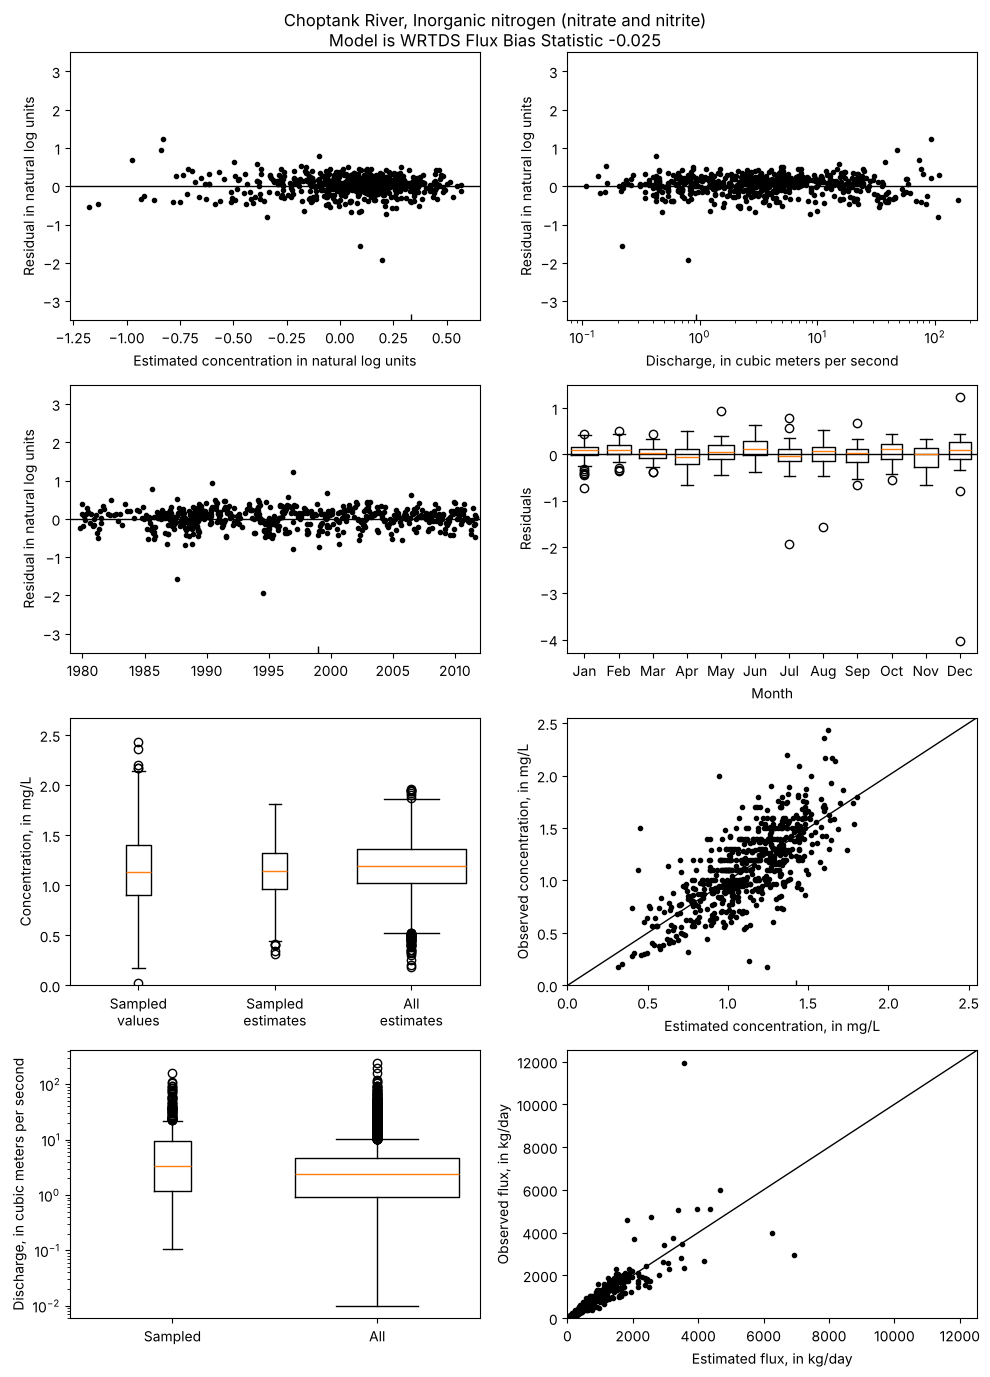

In [10]:
fig, axes = plots.flux_bias_multi(elist)

## 6. Annual results and flow normalization

`table_results` reports, for each water year, the mean discharge, the mean
concentration and flux, and the **flow-normalized** concentration and flux.

Annual means jump around because some years are wet and some are dry.
Flow normalization removes that noise: for each day it averages the model's
estimate over all the discharges that have occurred on that day of the year,
so a year's flow-normalized value is what the concentration or flux would have
been with typical streamflow. The trend in the flow-normalized values is the
trend in the watershed.

In [11]:
from pyegret.analysis import table_results

annual = table_results(elist)


   Choptank River 
   Inorganic nitrogen (nitrate and nitrite)

   Water Year 

   Year   Discharge    Conc    FN_Conc     Flux    FN_Flux
            cms         mg/L             10^6 kg/yr

   1980      4.25     0.932     0.964     0.115     0.106
   1981      2.22      1.01     0.972    0.0663     0.108
   1982      3.05      1.02      0.98    0.0976     0.109
   1983      4.99         1      0.99     0.133     0.112
   1984      5.72      0.99         1      0.16     0.114
   1985      1.52      1.06      1.02    0.0489     0.116
   1986      2.63      1.05      1.03    0.0902     0.118
   1987      3.37      1.06      1.04     0.114     0.121
   1988      1.87      1.12      1.08    0.0658     0.124
   1989      5.61      1.06      1.12     0.164     0.128
   1990      4.01      1.13      1.14     0.137     0.131
   1991      2.75      1.19      1.16    0.0996     0.132
   1992      2.19      1.23      1.18    0.0826     0.134
   1993      3.73      1.25       1.2     0.134     0

The same results as figures: dots are annual means, and the line is the
flow-normalized value. Flux is in millions of kilograms per year by default
(`flux_unit=9`); EGRET's other units are available by number or by name.

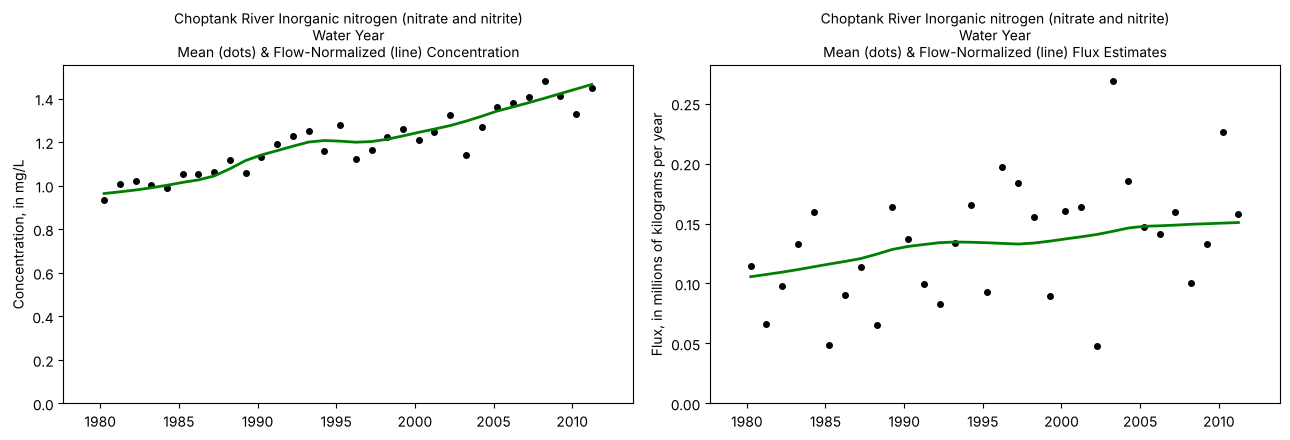

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
plots.plot_conc_hist(elist, ax=ax1)
plots.plot_flux_hist(elist, ax=ax2)
fig.tight_layout()

`table_change` turns the flow-normalized series into changes between chosen
years, in absolute terms and in percent, with slopes per year.

In [13]:
from pyegret.analysis import table_change

changes = table_change(elist, year_points=[1985, 1995, 2005, 2010])


   Choptank River 
   Inorganic nitrogen (nitrate and nitrite)

   Water Year 

           Concentration trends
   time span       change     slope    change     slope
                     mg/L   mg/L/yr        %       %/yr
 1985  to  1995      0.19     0.019        19       1.9
 1985  to  2005      0.33     0.016        32       1.6
 1985  to  2010      0.43     0.017        42       1.7
 1995  to  2005      0.14     0.014        12       1.2
 1995  to  2010      0.24     0.016        20       1.3
 2005  to  2010       0.1      0.02       7.5       1.5

                 Flux Trends
   time span          change        slope       change        slope
              10^6 kg/yr 10^6 kg/yr/yr      %         %/yr
 1985  to  1995        0.018       0.0018           15          1.5
 1985  to  2005        0.031       0.0016           27          1.4
 1985  to  2010        0.034       0.0014           29          1.2
 1995  to  2005        0.014       0.0014           10            1
 1995  to 

## 7. How the concentration-discharge relationship changed

The fitted surface itself shows where in time, season and discharge the
change happened. `plot_contours` draws it with concentration in color; the
black lines mark the 5th and 95th percentile of discharge for each time of
year, so the part of the surface between them is where the river actually
spends its time. As in EGRET's vignette, we choose the contour levels
ourselves, because the default spans the whole surface, including corners
the river never visits.

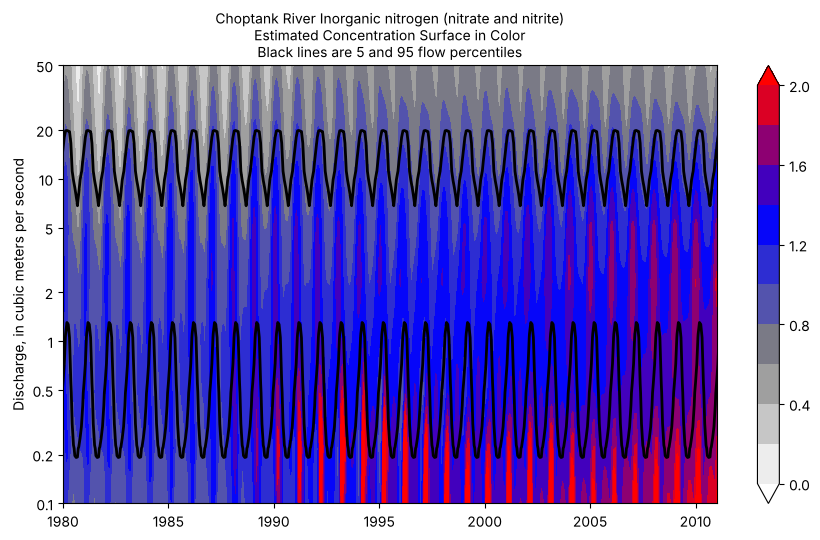

In [14]:
levels = np.linspace(0.0, 2.0, 11)
fig, ax = plots.plot_contours(elist, 1980, 2011, q_bottom=0.1, q_top=50,
                              contour_levels=levels)

The surface has shifted from blue toward red over the years, most visibly at
low and moderate flows. `plot_diff_contours` shows the change directly, here
from 1985 to 2010 through a calendar year. Concentration rose at almost every
combination of season and discharge, by the most at low flows from late summer
into winter, and hardly at all at the high flows of late winter and early
spring.

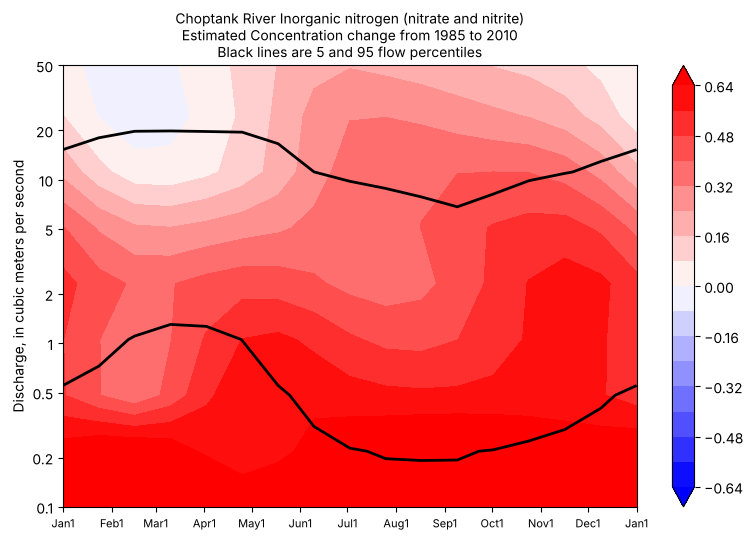

In [15]:
fig, ax = plots.plot_diff_contours(elist, 1985, 2010, q_bottom=0.1, q_top=50,
                                   max_diff=0.6)

A third view: the modeled concentration against discharge on the same day of
the year in three different years. Each curve is a WRTDS regression evaluated
at that date, so the gap between the curves is the change at a given flow. On
April 1, concentration at low and moderate flows rose by roughly half between
1985 and 2010, while at the highest flows the three curves come together.
The discharge range is kept to flows the river actually has in early April;
below about 0.5 m3/s the regression would be extrapolating.

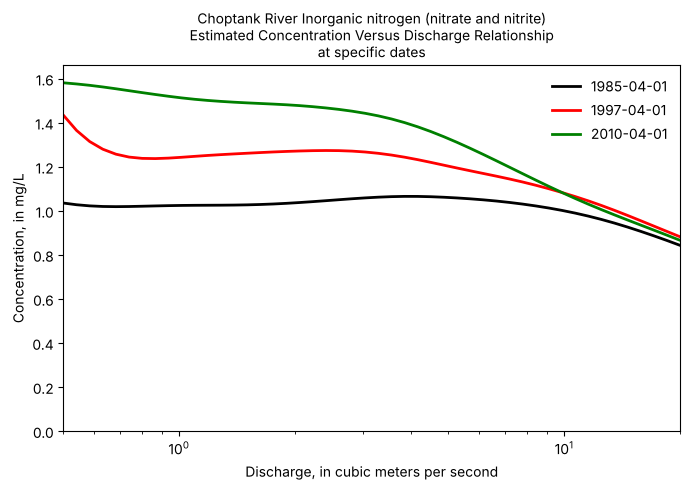

In [16]:
fig, ax = plots.plot_conc_q_smooth(elist, "1985-04-01", "1997-04-01", "2010-04-01",
                                   q_low=0.5, q_high=20)

## 8. Separating the watershed from the weather: `run_pairs`

Flow normalization as above uses the whole discharge record for every year,
which assumes the distribution of streamflow has not changed. Often it has.
**Generalized flow normalization** (Choquette and others, 2019) instead uses,
for each year, only the discharges from a window around it: `window_side=7`
means seven years on either side, which is EGRET's suggestion.

`run_pairs` compares two years this way and splits the total change in two:

- the **concentration-discharge trend component (CQTC)**, the change that
  comes from the watershed, with streamflow held the same; and
- the **discharge trend component (QTC)**, the change that comes from the
  streamflow itself having changed.

`window_side` has no default, as in R, so you must choose it.

In [17]:
from pyegret.analysis import run_pairs

pairs = run_pairs(elist, 1985, 2010, window_side=7)

Sample1 has 606 Samples and 605 are uncensored
Sample2 has 606 Samples and 605 are uncensored
minNumObs has been set to 100 minNumUncen has been set to 50



   Choptank River 
   Inorganic nitrogen (nitrate and nitrite)

   Water Year 

 Change estimates  2010  minus  1985 

 For concentration: total change is  0.396 mg/L
 expressed as Percent Change is  +38.52 %

 Concentration v. Q Trend Component  +41.64 %
       Q Trend Component             -3.13 % 


 For flux: total change is  0.0542 million kg/year
 expressed as Percent Change is  +50.60 %

 Concentration v. Q Trend Component  +31.86 %
       Q Trend Component             +18.74 % 

      TotalChange  CQTC    QTC  x10  x11  x20  x22
Conc          0.4  0.43 -0.032    1    1  1.4  1.4
Flux        0.054 0.034   0.02 0.12 0.11 0.15 0.16


From 1985 to 2010, flow-normalized concentration rose by 38.5 %. The
watershed component alone (CQTC) is +41.6 %, and the change in streamflow
offset a little of it (QTC, -3.1 %). Flux rose by more, 50.6 %, and here
streamflow mattered: the river carried more water in the later window, and
that change in streamflow accounts for 18.7 of those percentage points. For
the same call R EGRET reports a total change in concentration of +38.6 %, so
PyEGRET agrees with it to about a tenth of a percentage point.

Compare `table_change` above, which with stationary flow normalization gave
+42 % for concentration and only +29 % for flux over the same years: holding
the streamflow distribution fixed hides the part of the increase in load that
came from wetter years.

The numbers are also returned, for use in your own tables: `x10` and `x20` are
the flow-normalized values of the two years with the whole discharge record,
and `x11` and `x22` are the values with each year's own window.

In [18]:
pairs["pairResults"]

,TotalChange,CQTC,QTC,x10,x11,x20,x22
Conc,0.396365,0.428557,-0.032192,1.015056,1.029091,1.443614,1.425457
Flux,0.054192,0.034125,0.020067,0.116218,0.107101,0.150343,0.161293


`run_groups` does the same for two groups of years (say 1980-1990 against
2001-2011), and `run_series` produces the whole annual series with generalized
flow normalization. Plotted next to the stationary version, the difference is
small for concentration but clear for flux, which is what `run_pairs` found.

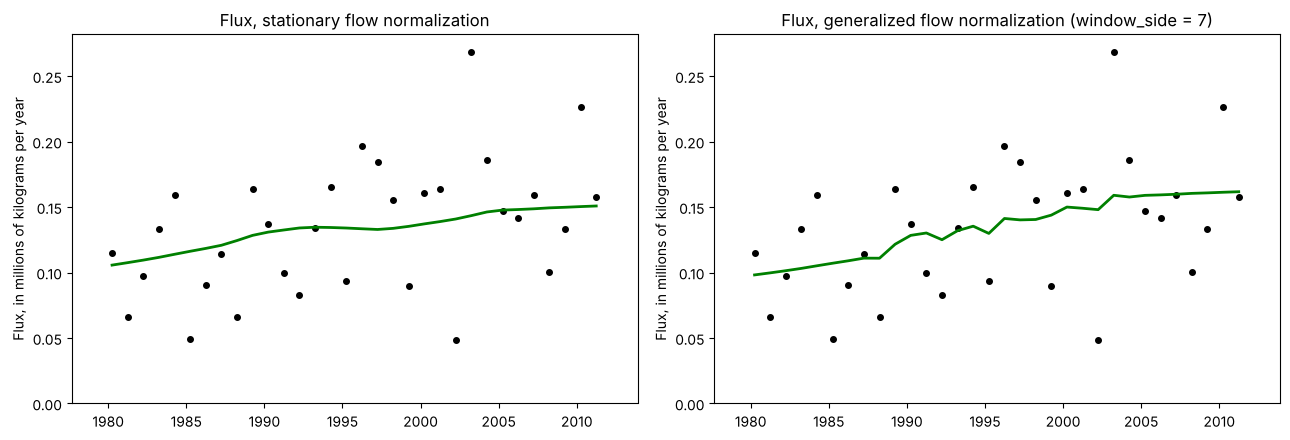

In [19]:
from pyegret.analysis import run_series

series = run_series(elist, window_side=7, verbose=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plots.plot_flux_hist(elist, ax=axes[0])
axes[0].set_title("Flux, stationary flow normalization")
plots.plot_flux_hist(series, ax=axes[1])
axes[1].set_title("Flux, generalized flow normalization (window_side = 7)")
fig.tight_layout()

## 9. WRTDS-Kalman: the best estimate of what actually happened

Flow-normalized values are for trends. When the question is instead *how much
nitrogen did the river actually carry in 2003*, WRTDS-Kalman (Zhang and
Hirsch, 2019) gives a better answer. It uses the fact that the model's
residuals are correlated from one day to the next: on a day when the sample
came in above the model, the days around it were probably above the model too.
`wrtds_kalman` fills in the days between samples by simulation, many times
over, and averages. Because of the random draws the result changes slightly
from run to run; `seed` makes it repeatable.

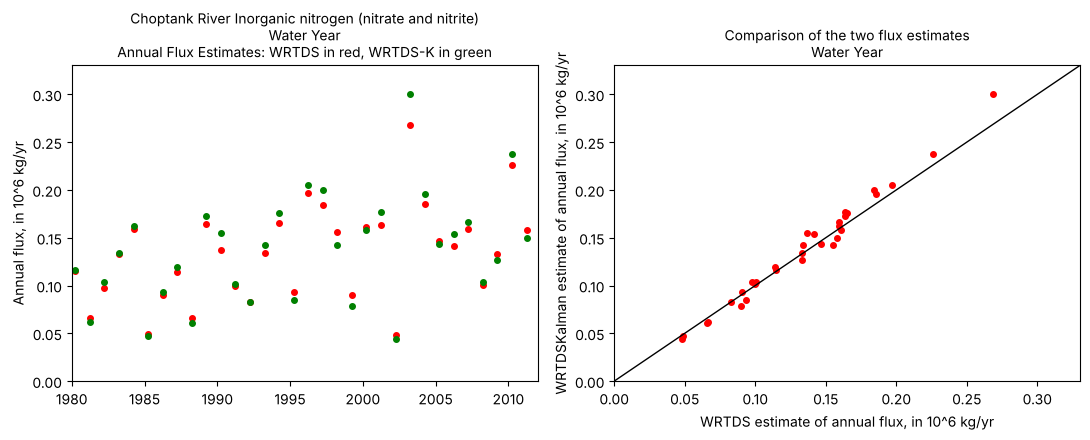

In [20]:
from pyegret import wrtds_kalman

kalman = wrtds_kalman(elist, seed=1, verbose=False)
fig, axes = plots.plot_wrtds_kalman(kalman, side_by_side=True)

Over a couple of years of daily values the difference is easy to see. The top
panel is the WRTDS estimate alone, and the bottom one is WRTDS-Kalman, which
bends toward each sample and carries that information to the days around it.

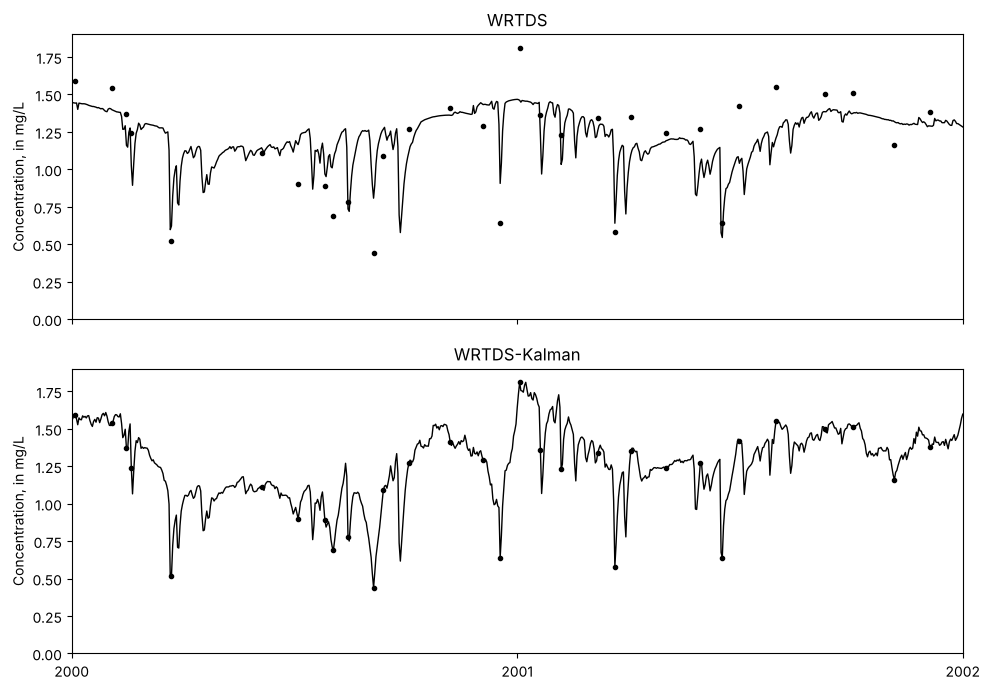

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
plots.plot_conc_time_daily(kalman, 2000, 2002, plot_gen_conc=False, print_title=False,
                           ax=axes[0])
axes[0].set_title("WRTDS")
plots.plot_conc_time_daily(kalman, 2000, 2002, print_title=False, ax=axes[1])
axes[1].set_title("WRTDS-Kalman")
fig.tight_layout()

## Where to go next

- **Tutorial 2** shows how to bring in your own data: file formats, censored
  values, units, and the checks to run before fitting.
- `docs/r_to_python.md` lists every EGRET function with its PyEGRET name, and
  every function's docstring says which R function it mirrors, for example
  `help(pyegret.analysis.run_pairs)`.
- A change reported by `run_pairs` is an estimate. For its confidence
  interval and p-value, pass the result to `pyegret.ci.run_pairs_boot`, the
  translation of R's EGRETci; `pyegret.ci.ci_calculations` puts confidence
  bands on the flow-normalized history. Both refit the model many times, so
  they take minutes rather than seconds.

**Data:** U.S. Geological Survey, as distributed with EGRET
(`Choptank_eList`). **Method:** Hirsch, Moyer and Archfield (2010); Hirsch and
De Cicco (2015); Choquette and others (2019) for generalized flow
normalization; Zhang and Hirsch (2019) for WRTDS-Kalman. Full citations are in
the repository's `NOTICE.md`.